# Mejora de CNN y comparación con SVM y Random Forest

Usamos exclusivamente **`data/base/`**: las mismas 291 imágenes, etiquetas y 22 grupos de los cuadernos 06/07. La CNN recibe sus recortes RGB de 224×224; SVM y Random Forest mantienen las 43 características y sus predicciones externas verificadas.

**Diseño fijado antes de esta corrida:** MobileNetV3 Small preentrenada en ImageNet con extractor congelado. Se entrenan seis combinaciones de cabezal (lineal o MLP de 64 unidades) y ponderación de clases (exponentes 0, 0,5 y 1). Cada configuración tiene hasta 120 épocas, mínimo de selección 12 y paciencia 15. La selección usa hasta tres divisiones internas por grupos, dentro de los mismos tres bloques externos con semilla 42. El bloque externo se predice al terminar; no selecciona parámetros ni épocas.

La CNN simple anterior se conserva como referencia de predicciones dentro de este informe. La CNN actual reemplaza sus pesos en la misma carpeta. Las métricas pertenecen al desarrollo: estas imágenes se usaron para revisar etiquetas y máscaras; una prueba final necesita capturas independientes.

In [1]:
from pathlib import Path
import json
import sys

# Buscar la raíz por archivos versionados, sin exigir datos generados.
candidatos = [Path.cwd(), *Path.cwd().parents]
candidatos += [p / 'proyecto_estado_frutas' for p in candidatos.copy()]
PROYECTO = next((p for p in candidatos if (p / 'config/alcance_actual.json').is_file() and (p / 'src').is_dir()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde la carpeta del proyecto o notebooks/.')
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

import json
import pandas as pd
from IPython.display import Image, Markdown, display
from dataclasses import asdict
from src.data.base import cargar_base, verificar_imagenes
from src.models.cnn_calidad import candidatos_transferencia
from src.training.entrenar_modelos import ejecutar_comparacion

SALIDA = PROYECTO / 'experiments/results/comparacion_modelos'
CHECKPOINTS = PROYECTO / 'experiments/checkpoints/comparacion_modelos'
MAX_EPOCAS = 120
HILOS_CPU = 4
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
base, columnas, estado = cargar_base(PROYECTO)
verificar_imagenes(base)
print(f'Base: {len(base)} imágenes, {len(columnas)} características tradicionales y {base.grupo_particion.nunique()} grupos.')
print('SHA:', estado['sha_base'])
display(pd.DataFrame([asdict(c) for c in candidatos_transferencia(MAX_EPOCAS)]))

Base: 291 imágenes, 43 características tradicionales y 22 grupos.
SHA: ce36085062344eed79c95062be33b2410b4320a600dbe517db849c4e71414de1


,cabezal,potencia_peso,lr,weight_decay,dropout,max_epocas,min_epocas,paciencia
0,lineal,0.0,0.003,0.01,0.2,120,12,15
1,lineal,0.5,0.003,0.01,0.2,120,12,15
2,lineal,1.0,0.003,0.01,0.2,120,12,15
3,mlp,0.0,0.003,0.01,0.2,120,12,15
4,mlp,0.5,0.003,0.01,0.2,120,12,15
5,mlp,1.0,0.003,0.01,0.2,120,12,15


## Entrenamiento real sobre la base del proyecto

El extractor convolucional preentrenado y sus estadísticas BatchNorm permanecen fijos. El nuevo cabezal aprende las tres calidades con AdamW, normalización LayerNorm sin parámetros, dropout 0,2, tasa 0,003 y regularización 0,01. La normalización de imagen usa las constantes de ImageNet, conservando todo el recorte preparado.

Para reducir el cálculo en CPU se guardan los vectores de cinco vistas fijas: original, espejo horizontal, giros de ±10° y brillo 0,92. Cada época toma una vista por imagen de entrenamiento. La validación solo usa la original. El cache no aprende estadísticas de la base ni utiliza etiquetas. Los pesos de clase se calculan solo con el entrenamiento de cada ajuste.

Se guardan plan, particiones, búsquedas internas, curvas y pesos en las carpetas existentes de comparación. Una selección interna adicional sobre toda la base fija los parámetros y la duración del prototipo final. [Transferencia en PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial) y [MobileNetV3 Small](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html).

In [2]:
tablas = ejecutar_comparacion(PROYECTO, incluir_cnn=True, max_epocas_cnn=MAX_EPOCAS, hilos_cpu=HILOS_CPU)
display(tablas['metricas_globales'])
display(tablas['metricas_pliegues'])

Referencias tradicionales verificadas: misma base, imágenes, grupos y pliegues.


CNN transferencia: {'fase': 'seleccion_interna', 'exterior': 1, 'candidato': 1}


CNN transferencia: {'fase': 'seleccion_interna', 'exterior': 1, 'candidato': 2}


CNN transferencia: {'fase': 'seleccion_interna', 'exterior': 1, 'candidato': 3}


CNN transferencia: {'fase': 'seleccion_interna', 'exterior': 1, 'candidato': 4}


CNN transferencia: {'fase': 'seleccion_interna', 'exterior': 1, 'candidato': 5}


... (21 outputs left out)

CNN transferencia: {'fase': 'seleccion_global', 'exterior': 0, 'candidato': 6}


CNN transferencia: {'fase': 'completado', 'imagenes_oof': 291}


,modelo,imagenes,exactitud,f1_macro,recall_macro,exactitud_peso_grupo,f1_macro_peso_grupo,recall_macro_peso_grupo
0,Referencia_mayoritaria,291,0.6907,0.2724,0.3333,0.5343,0.2322,0.3333
1,SVM_inicial,291,0.3952,0.2986,0.3653,0.4153,0.3675,0.3878
2,Random_Forest_inicial,291,0.5464,0.4288,0.4794,0.4472,0.4048,0.4376
3,SVM_ajustado,291,0.4467,0.3730,0.4135,0.4447,0.3739,0.3983
4,Random_Forest_ajustado,291,0.4433,0.3877,0.4297,0.4057,0.3665,0.4083
5,CNN_simple,291,0.2715,0.2367,0.3926,0.3658,0.3571,0.4134
6,CNN_transferencia,291,0.7045,0.4725,0.5006,0.6278,0.5313,0.5235


,modelo,pliegue,n_train,n_validacion,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,1,182,109,0.9450,0.3239,0.3333
1,Referencia_mayoritaria,2,202,89,0.8539,0.3071,0.3333
2,Referencia_mayoritaria,3,198,93,0.2366,0.1275,0.3333
3,SVM_inicial,1,182,109,0.8257,0.3630,0.4515
4,SVM_inicial,2,202,89,0.1124,0.1438,0.2406
5,SVM_inicial,3,198,93,0.1613,0.1682,0.4186
6,Random_Forest_inicial,1,182,109,0.9450,0.4734,0.4935
7,Random_Forest_inicial,2,202,89,0.4607,0.4161,0.5142
8,Random_Forest_inicial,3,198,93,0.1613,0.2223,0.4288
9,SVM_ajustado,1,182,109,0.3119,0.2498,0.2702


## Comparación fuera del entrenamiento

Cada imagen tiene una predicción por modelo obtenida sin que su grupo estuviera en el entrenamiento correspondiente. F1 macro y recall macro dan el mismo peso a las tres calidades. La exactitud se interpreta junto con esas métricas porque el 69,1 % de las imágenes son buenas. Las métricas con peso por grupo exploran la influencia de las campañas grandes.

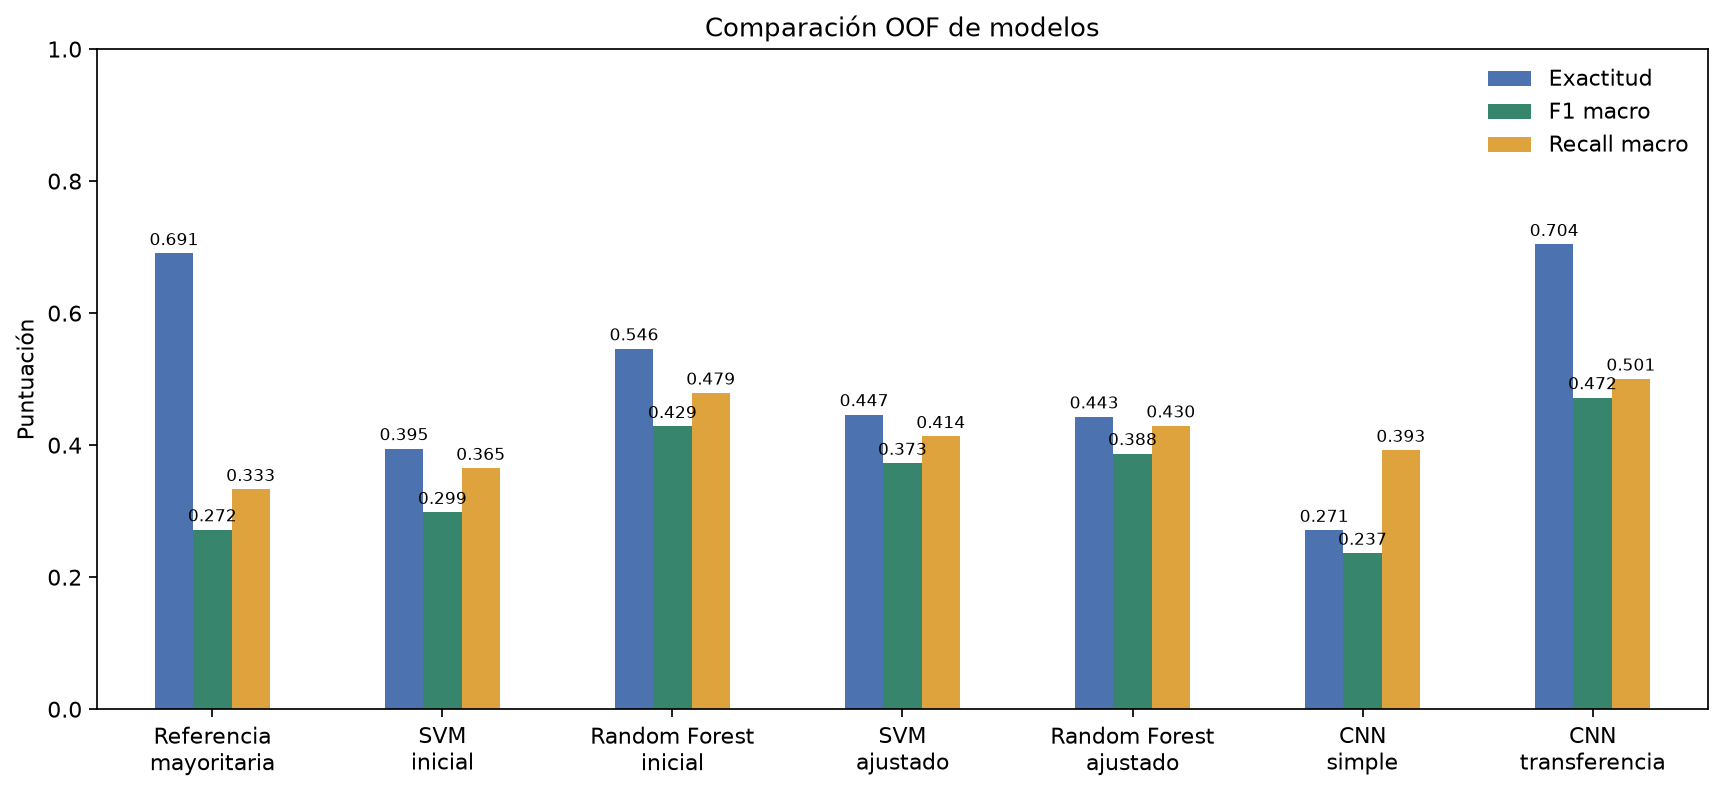

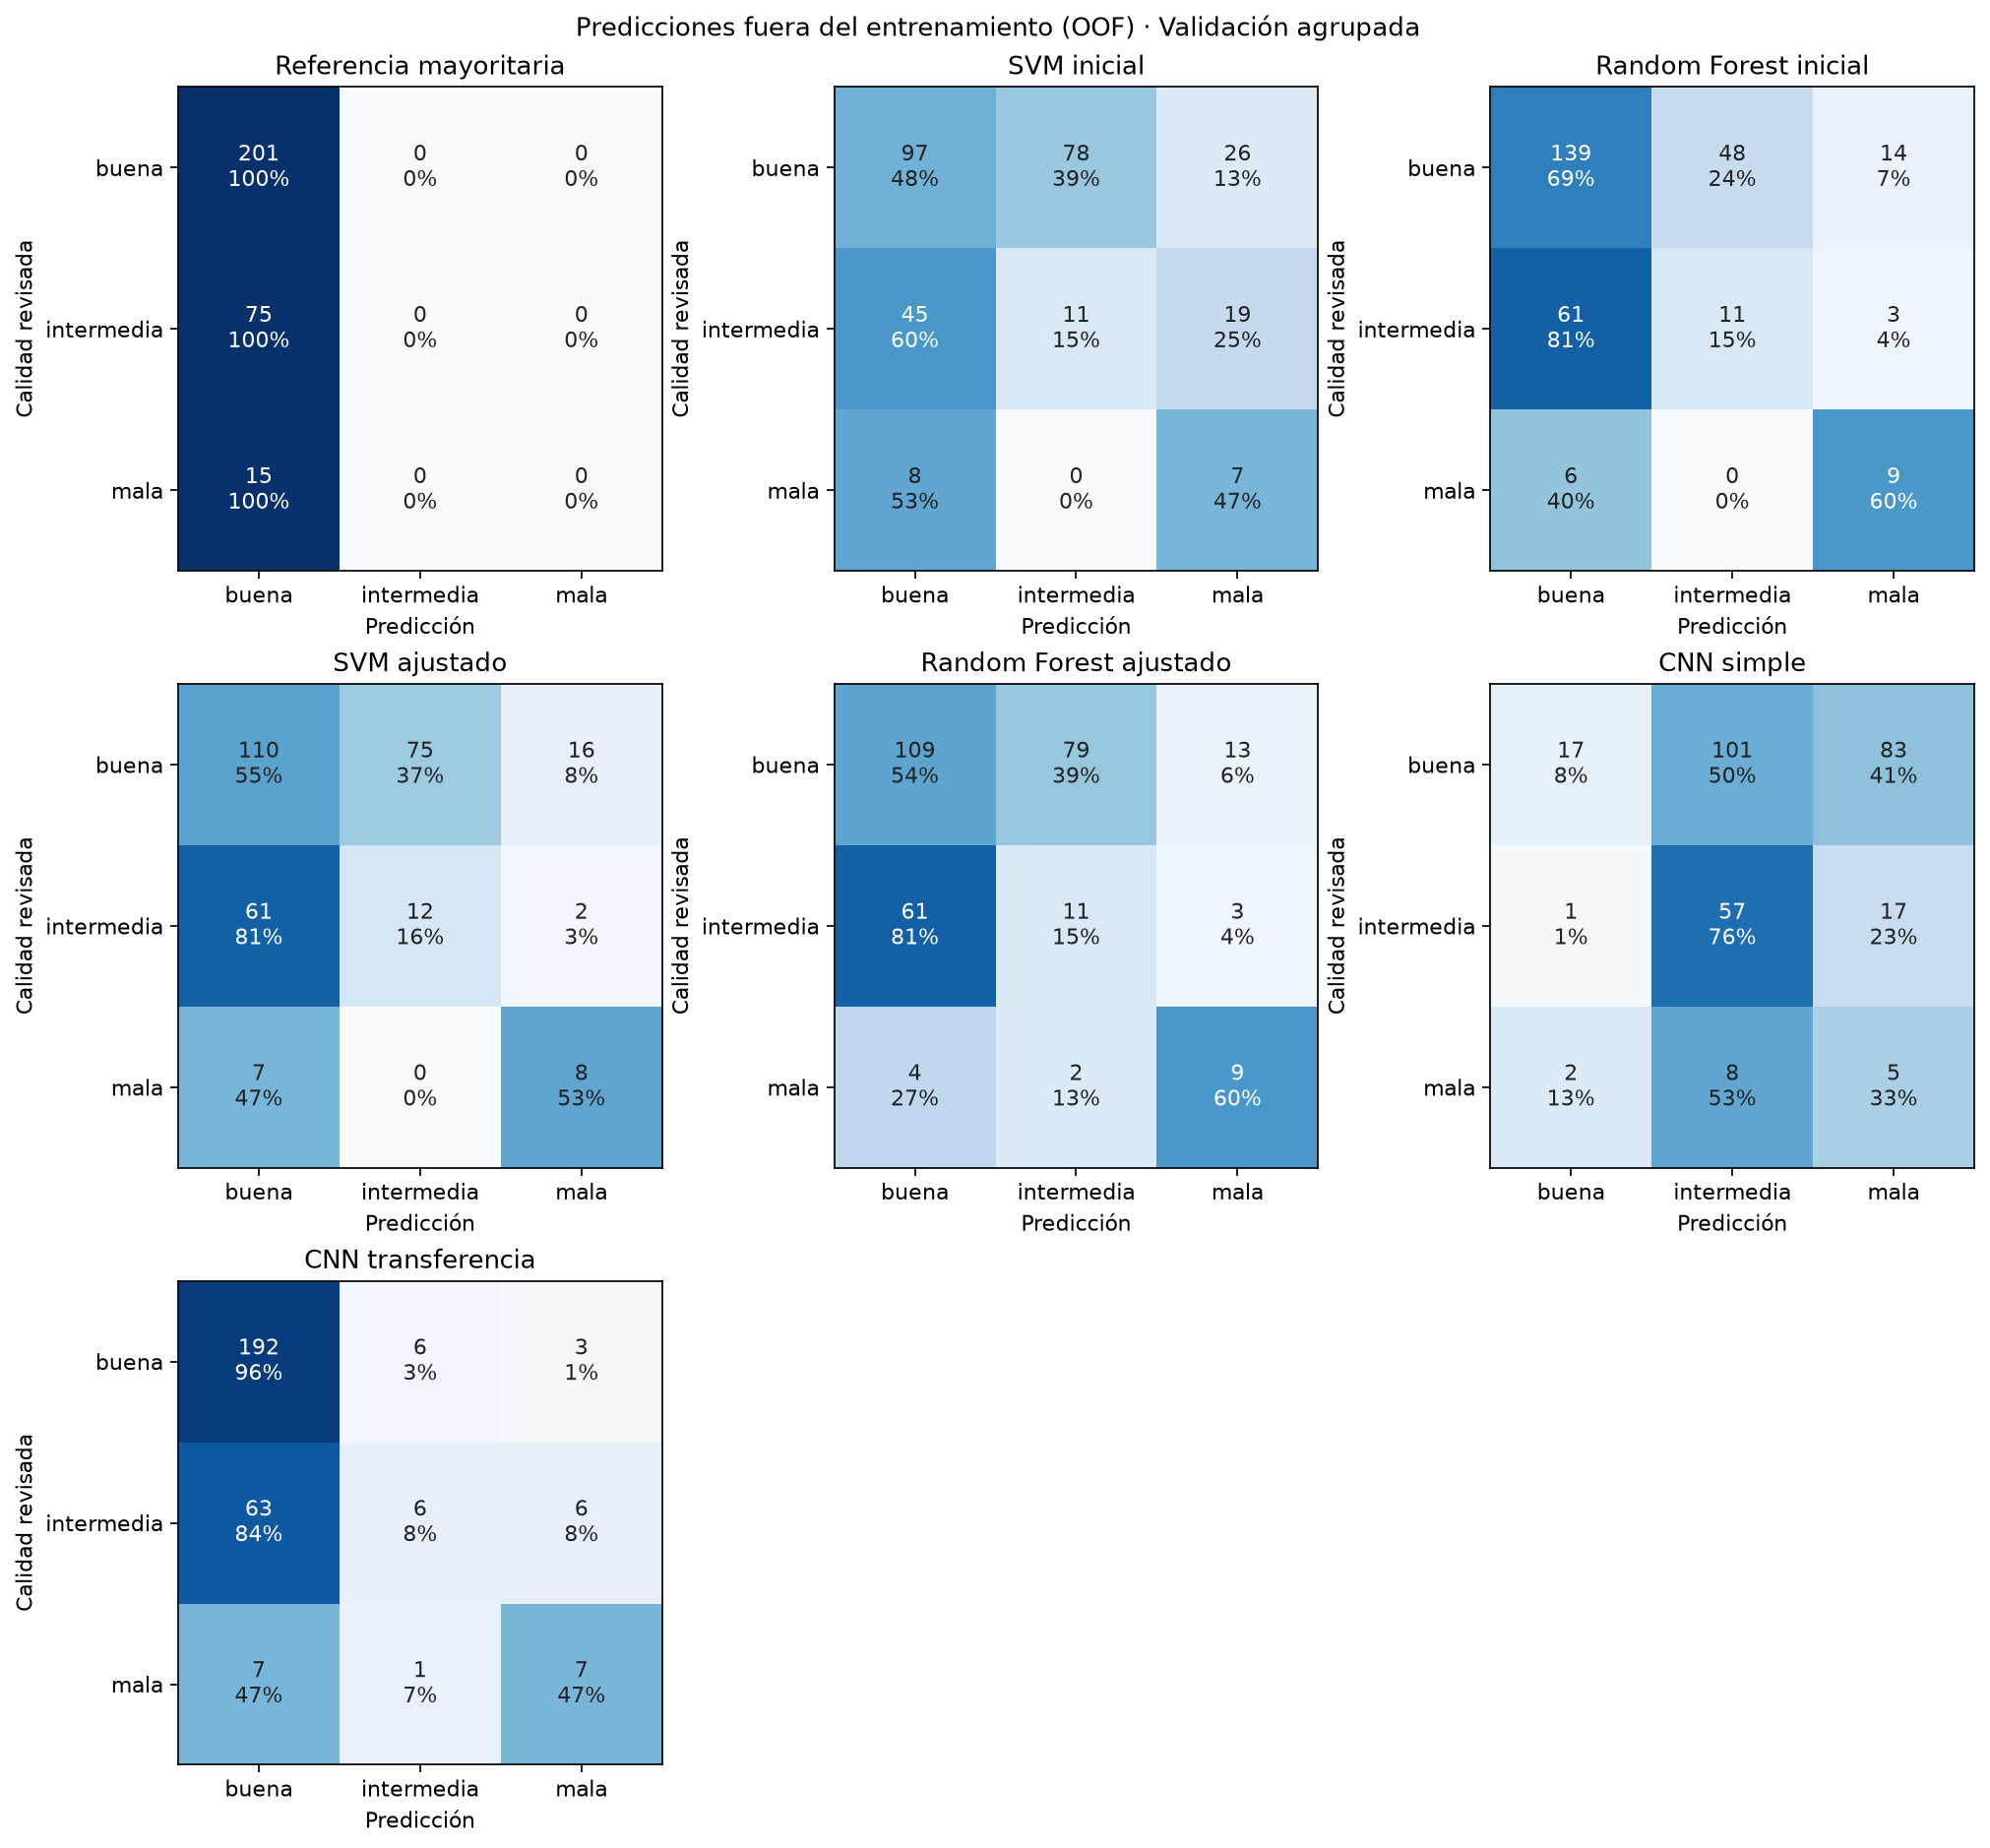

,modelo,calidad,imagenes,recall,f1
0,Referencia_mayoritaria,buena,201,1.0000,0.8171
1,Referencia_mayoritaria,intermedia,75,0.0000,0.0000
2,Referencia_mayoritaria,mala,15,0.0000,0.0000
3,SVM_inicial,buena,201,0.4826,0.5527
4,SVM_inicial,intermedia,75,0.1467,0.1341
5,SVM_inicial,mala,15,0.4667,0.2090
6,Random_Forest_inicial,buena,201,0.6915,0.6830
7,Random_Forest_inicial,intermedia,75,0.1467,0.1642
8,Random_Forest_inicial,mala,15,0.6000,0.4390
9,SVM_ajustado,buena,201,0.5473,0.5805


,modelo,fruta,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,banano,83,0.0964,0.0586,0.3333
1,Referencia_mayoritaria,limon,77,0.9351,0.3221,0.3333
2,Referencia_mayoritaria,manzana,131,0.9237,0.3201,0.3333
3,SVM_inicial,banano,83,0.1687,0.1576,0.3012
4,SVM_inicial,limon,77,0.0519,0.0353,0.3426
5,SVM_inicial,manzana,131,0.7405,0.3727,0.4915
6,Random_Forest_inicial,banano,83,0.1566,0.2619,0.2845
7,Random_Forest_inicial,limon,77,0.4545,0.2347,0.4861
8,Random_Forest_inicial,manzana,131,0.8473,0.4538,0.5750
9,SVM_ajustado,banano,83,0.1807,0.2899,0.2571


,modelo,fuente,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,propia,25,0.6000,0.2500,0.3333
1,Referencia_mayoritaria,publica,245,0.7265,0.2805,0.3333
2,Referencia_mayoritaria,publica_kaggle,21,0.3810,0.1839,0.3333
3,SVM_inicial,propia,25,0.4800,0.4870,0.6528
4,SVM_inicial,publica,245,0.3918,0.2265,0.2046
5,SVM_inicial,publica_kaggle,21,0.3333,0.3119,0.3175
6,Random_Forest_inicial,propia,25,0.4800,0.5259,0.6528
7,Random_Forest_inicial,publica,245,0.5714,0.2795,0.2839
8,Random_Forest_inicial,publica_kaggle,21,0.3333,0.3257,0.3433
9,SVM_ajustado,propia,25,0.4800,0.3483,0.3639


In [3]:
display(Image(filename=str(SALIDA / 'comparacion_modelos.png')))
display(Image(filename=str(SALIDA / 'matrices_confusion.png')))
display(tablas['metricas_por_clase'])
display(tablas['metricas_por_fruta'])
display(tablas['metricas_por_fuente'])

## Aprendizaje y selección de parámetros

Las curvas siguientes muestran el entrenamiento de cada bloque externo. La evaluación externa se hace después de terminarlo. Las tablas de búsqueda contienen puntuaciones internas; no son puntuaciones adicionales de prueba. El prototipo final puede tener una configuración distinta de la elegida en cada bloque.

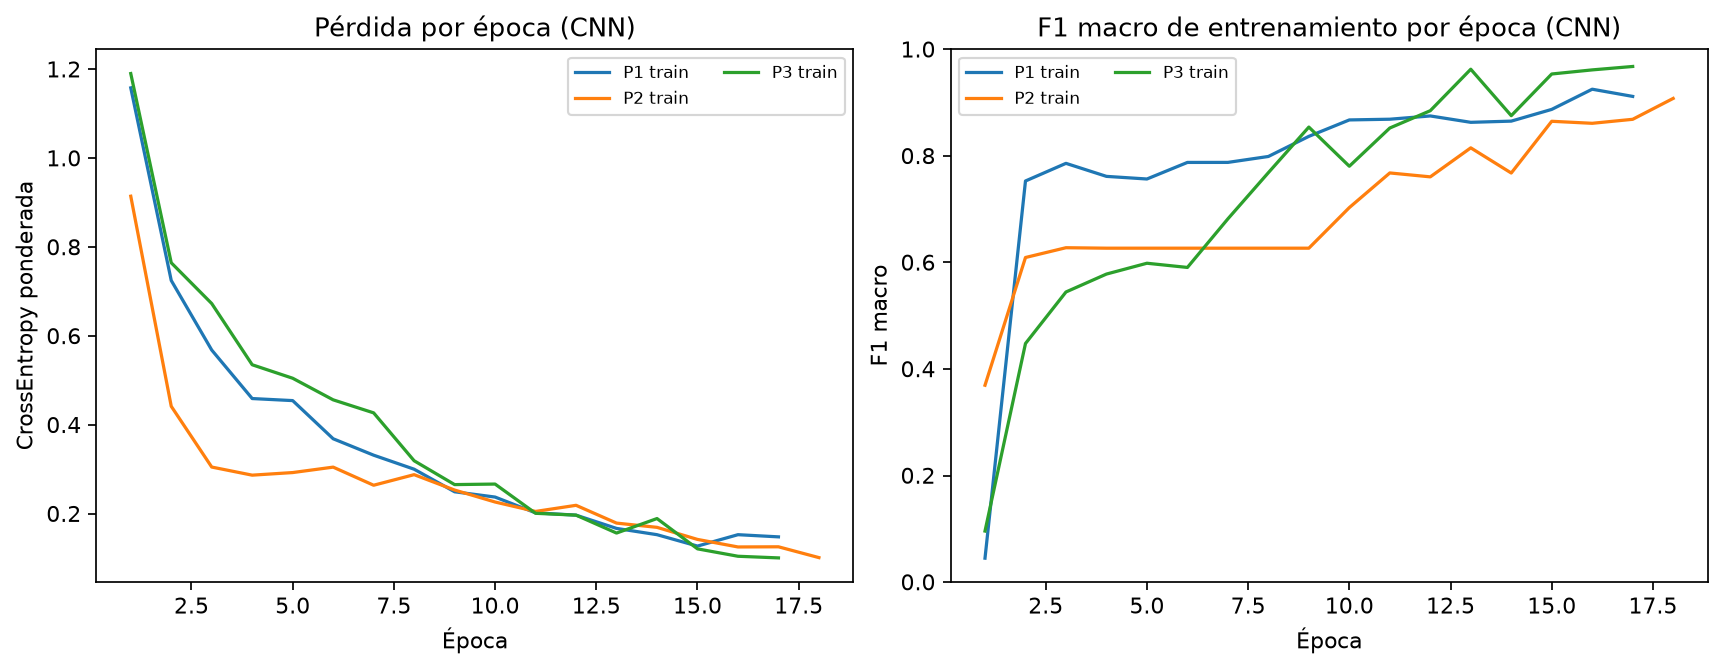

,exterior,cabezal,potencia_peso,lr,weight_decay,dropout,max_epocas,min_epocas,paciencia
0,1,mlp,1.0,0.003,0.01,0.2,17,12,15
1,2,lineal,0.0,0.003,0.01,0.2,18,12,15
2,3,mlp,0.5,0.003,0.01,0.2,17,12,15


,cabezal,potencia_peso,lr,weight_decay,dropout,max_epocas,min_epocas,paciencia,candidato,f1_macro_interno_medio,f1_macro_interno_std,epoca_media
0,lineal,1.0,0.003,0.01,0.2,120,12,15,3,0.6343,0.0766,23
1,lineal,0.5,0.003,0.01,0.2,120,12,15,2,0.6327,0.0732,19
2,mlp,1.0,0.003,0.01,0.2,120,12,15,6,0.6122,0.0482,14
3,lineal,0.0,0.003,0.01,0.2,120,12,15,1,0.5995,0.0310,33
4,mlp,0.5,0.003,0.01,0.2,120,12,15,5,0.4937,0.1299,13
5,mlp,0.0,0.003,0.01,0.2,120,12,15,4,0.4735,0.1253,19


Configuración final CNN: {'cabezal': 'lineal', 'potencia_peso': 1.0, 'lr': 0.003, 'weight_decay': 0.01, 'dropout': 0.2, 'max_epocas': 23, 'min_epocas': 12, 'paciencia': 15}
Dispositivo: cpu
Épocas finales: 23


In [4]:
display(Image(filename=str(SALIDA / 'curvas_entrenamiento_cnn.png')))
display(pd.read_csv(SALIDA / 'cnn_configuraciones_externas.csv'))
display(pd.read_csv(SALIDA / 'cnn_busqueda_global.csv'))
metadata = json.loads((SALIDA / 'configuracion_comparacion.json').read_text(encoding='utf-8'))
print('Configuración final CNN:', metadata['resumen_cnn']['mejor_config_global'])
print('Dispositivo:', metadata['resumen_cnn']['dispositivo'])
print('Épocas finales:', metadata['resumen_cnn']['epocas_finales'])

## Modelos guardados

La CNN final se guarda en la carpeta de comparación. Los modelos tradicionales conservan sus archivos de los cuadernos 06/07. Todas las referencias usan la misma huella de base. Cargar pesos permite preparar la inferencia; las métricas de comparación proceden de los modelos de cada bloque externo, no de predecir el entrenamiento con el modelo final.

In [5]:
import joblib
import torch
from src.models.cnn_calidad import CNNTransferencia, ConfigTransferencia, predecir_transferencia

rf = joblib.load(PROYECTO / 'experiments/checkpoints/modelos_tradicionales/random_forest.joblib')
paquete = torch.load(CHECKPOINTS / 'cnn_calidad.pt', map_location='cpu', weights_only=True)
assert rf['sha_base'] == paquete['sha_base'] == estado['sha_base']
assert paquete['arquitectura'] == 'mobilenet_v3_small_congelada'
cnn = CNNTransferencia(ConfigTransferencia(**paquete['config']))
cnn.load_state_dict(paquete['state_dict'])
cnn.eval()
ejemplo, _ = predecir_transferencia(cnn, [Path(base.iloc[0].ruta_cnn)])
print('CNN recargada correctamente. Predicción de ejemplo:', ejemplo[0])
print('La recarga incluye todos los pesos; no necesita descargar ImageNet.')
print('Este ejemplo no se usa para calcular las métricas.')

CNN recargada correctamente. Predicción de ejemplo: intermedia
La recarga incluye todos los pesos; no necesita descargar ImageNet.
Este ejemplo no se usa para calcular las métricas.


## Conclusión de la comparación

La siguiente celda calcula la diferencia respecto a la CNN anterior, SVM ajustado y Random Forest inicial. Deben interpretarse también las métricas por calidad, fruta, fuente y grupo. Las pocas imágenes malas y la concentración de intermedias en una campaña limitan la generalización.

El F1 de las búsquedas internas sirve para seleccionar el entrenamiento. La cifra de comparación procede de las predicciones externas, sin usar esos grupos durante el ajuste correspondiente. Los parámetros de esta corrida no se vuelven a ajustar según sus puntuaciones externas.

**Resultado observado:** CNN actual obtiene F1 macro **0,472** y
exactitud **70,4 %**, frente a **0,237** de la CNN
anterior, **0,373** de SVM ajustado y
**0,429** de Random Forest inicial. Reconoce 192/201 buenas,
6/75 intermedias y 7/15 malas. El F1 con peso igual por grupo es
**0,531**, frente a **0,405** de RF.
La calidad intermedia requiere más datos independientes. El prototipo final
seleccionó cabezal `lineal`, peso `1.0` y
23 épocas mediante validación interna.

In [6]:
metricas = tablas['metricas_globales'].set_index('modelo')
cnn_f1 = metricas.loc['CNN_transferencia', 'f1_macro']
for nombre in ['CNN_simple', 'SVM_ajustado', 'Random_Forest_inicial']:
    if nombre in metricas.index:
        valor = metricas.loc[nombre, 'f1_macro']
        display(Markdown(f"**CNN actual frente a {nombre.replace('_', ' ')}:** F1 macro {cnn_f1:.3f} frente a {valor:.3f}; diferencia {cnn_f1-valor:+.3f}."))
display(tablas['metricas_por_clase'].query("modelo == 'CNN_transferencia'"))
display(Markdown('Esta comparación pertenece al desarrollo y conserva los grupos actuales. Una prueba final requiere capturas independientes reservadas antes de ajustar el procesamiento.'))

**CNN actual frente a CNN simple:** F1 macro 0.472 frente a 0.237; diferencia +0.236.

**CNN actual frente a SVM ajustado:** F1 macro 0.472 frente a 0.373; diferencia +0.099.

**CNN actual frente a Random Forest inicial:** F1 macro 0.472 frente a 0.429; diferencia +0.044.

,modelo,calidad,imagenes,recall,f1
18,CNN_transferencia,buena,201,0.9552,0.8294
19,CNN_transferencia,intermedia,75,0.0800,0.1364
20,CNN_transferencia,mala,15,0.4667,0.4516


Esta comparación pertenece al desarrollo y conserva los grupos actuales. Una prueba final requiere capturas independientes reservadas antes de ajustar el procesamiento.

## Diagnóstico de la calidad intermedia

La clase intermedia contiene 70 bananos, 3 manzanas y 2 limones. Una sola campaña reúne 67 de las 75 imágenes. El tercer bloque evalúa esa campaña y entrena con solo 8 intermedias, incluidas 3 de banano. Las tablas siguientes permiten distinguir errores de la CNN, falta de cobertura y dependencia entre fotografías.

La galería revisa doce ejemplos de la campaña dominante, repartidos por probabilidad de intermedia, y las ocho intermedias restantes. Las etiquetas se mantienen; las predicciones y probabilidades no determinan una corrección de etiqueta. La revisión visual debe distinguir madurez/color de defectos superficiales, extensión de lesiones y arrugamiento. Las anotaciones actuales proceden de una revisión visual única, sin acuerdo entre anotadores medido.

In [7]:
from scripts.diagnosticar_intermedia import ejecutar, verificar

diagnostico = ejecutar(PROYECTO, comparar_alternativas=True)
display(diagnostico['grupos_intermedia'])
display(diagnostico['cobertura'].query("calidad == 'intermedia'"))
print('Confusión de intermedias:', diagnostico['resumen']['confusion_intermedia'])
print('Pliegues internos reales:', diagnostico['resumen']['pliegues_internos_por_exterior'])
print('Ajustes internos CNN:', diagnostico['resumen']['ajustes_internos_cnn'])

Alternativa Logistica_CNN: bloque 1/3 terminado.


Alternativa Logistica_CNN: bloque 2/3 terminado.


Alternativa Logistica_CNN: bloque 3/3 terminado.


Alternativa SVM_CNN: bloque 1/3 terminado.


Alternativa SVM_CNN: bloque 2/3 terminado.


Alternativa SVM_CNN: bloque 3/3 terminado.


... (6 outputs left out)

Diagnóstico: {'sha_base': 'ce36085062344eed79c95062be33b2410b4320a600dbe517db849c4e71414de1', 'imagenes': 291, 'intermedias': 75, 'intermedias_por_fruta': {'banano': 70, 'manzana': 3, 'limon': 2}, 'grupos_con_intermedia': 5, 'grupo_dominante': 'b3614848dd857cd2', 'intermedias_grupo_dominante': 67, 'confusion_intermedia': {'buena': 63, 'intermedia': 6, 'mala': 6}, 'mediana_prob_intermedia': 0.12311486154794693, 'intermedias_predichas_buena_p_ge_09': 21, 'pliegues_internos_por_exterior': {'0': 3, '1': 3, '2': 2, '3': 3}, 'ajustes_internos_cnn': 66, 'cambio_etiquetas': False, 'evaluacion_independiente': False}


,grupo_particion,fruta,fuente,pliegue_validacion,imagenes,aciertos,prob_intermedia_media,recall_intermedia
0,03b4a5b0189f58cb,manzana,publica_kaggle,2,1,0,0.0210,0.0000
1,717c17ae4886b34b,manzana,publica_kaggle,1,2,0,0.0202,0.0000
2,94d8836cca0dfbac,limon,propia,2,2,0,0.0050,0.0000
3,b3614848dd857cd2,banano,publica,3,67,3,0.1743,0.0448
4,f5324b1335588796,banano,publica_kaggle,2,3,3,0.9096,1.0000


,pliegue,etapa,fruta,calidad,imagenes,grupos
1,1,entrenamiento,manzana,intermedia,1,1
4,1,entrenamiento,banano,intermedia,70,2
7,1,entrenamiento,limon,intermedia,2,1
10,1,validacion,manzana,intermedia,2,1
13,1,validacion,banano,intermedia,0,0
16,1,validacion,limon,intermedia,0,0
19,2,entrenamiento,manzana,intermedia,2,1
22,2,entrenamiento,banano,intermedia,67,1
25,2,entrenamiento,limon,intermedia,0,0
28,2,validacion,manzana,intermedia,1,1


Confusión de intermedias: {'buena': 63, 'intermedia': 6, 'mala': 6}
Pliegues internos reales: {'0': 3, '1': 3, '2': 2, '3': 3}
Ajustes internos CNN: 66


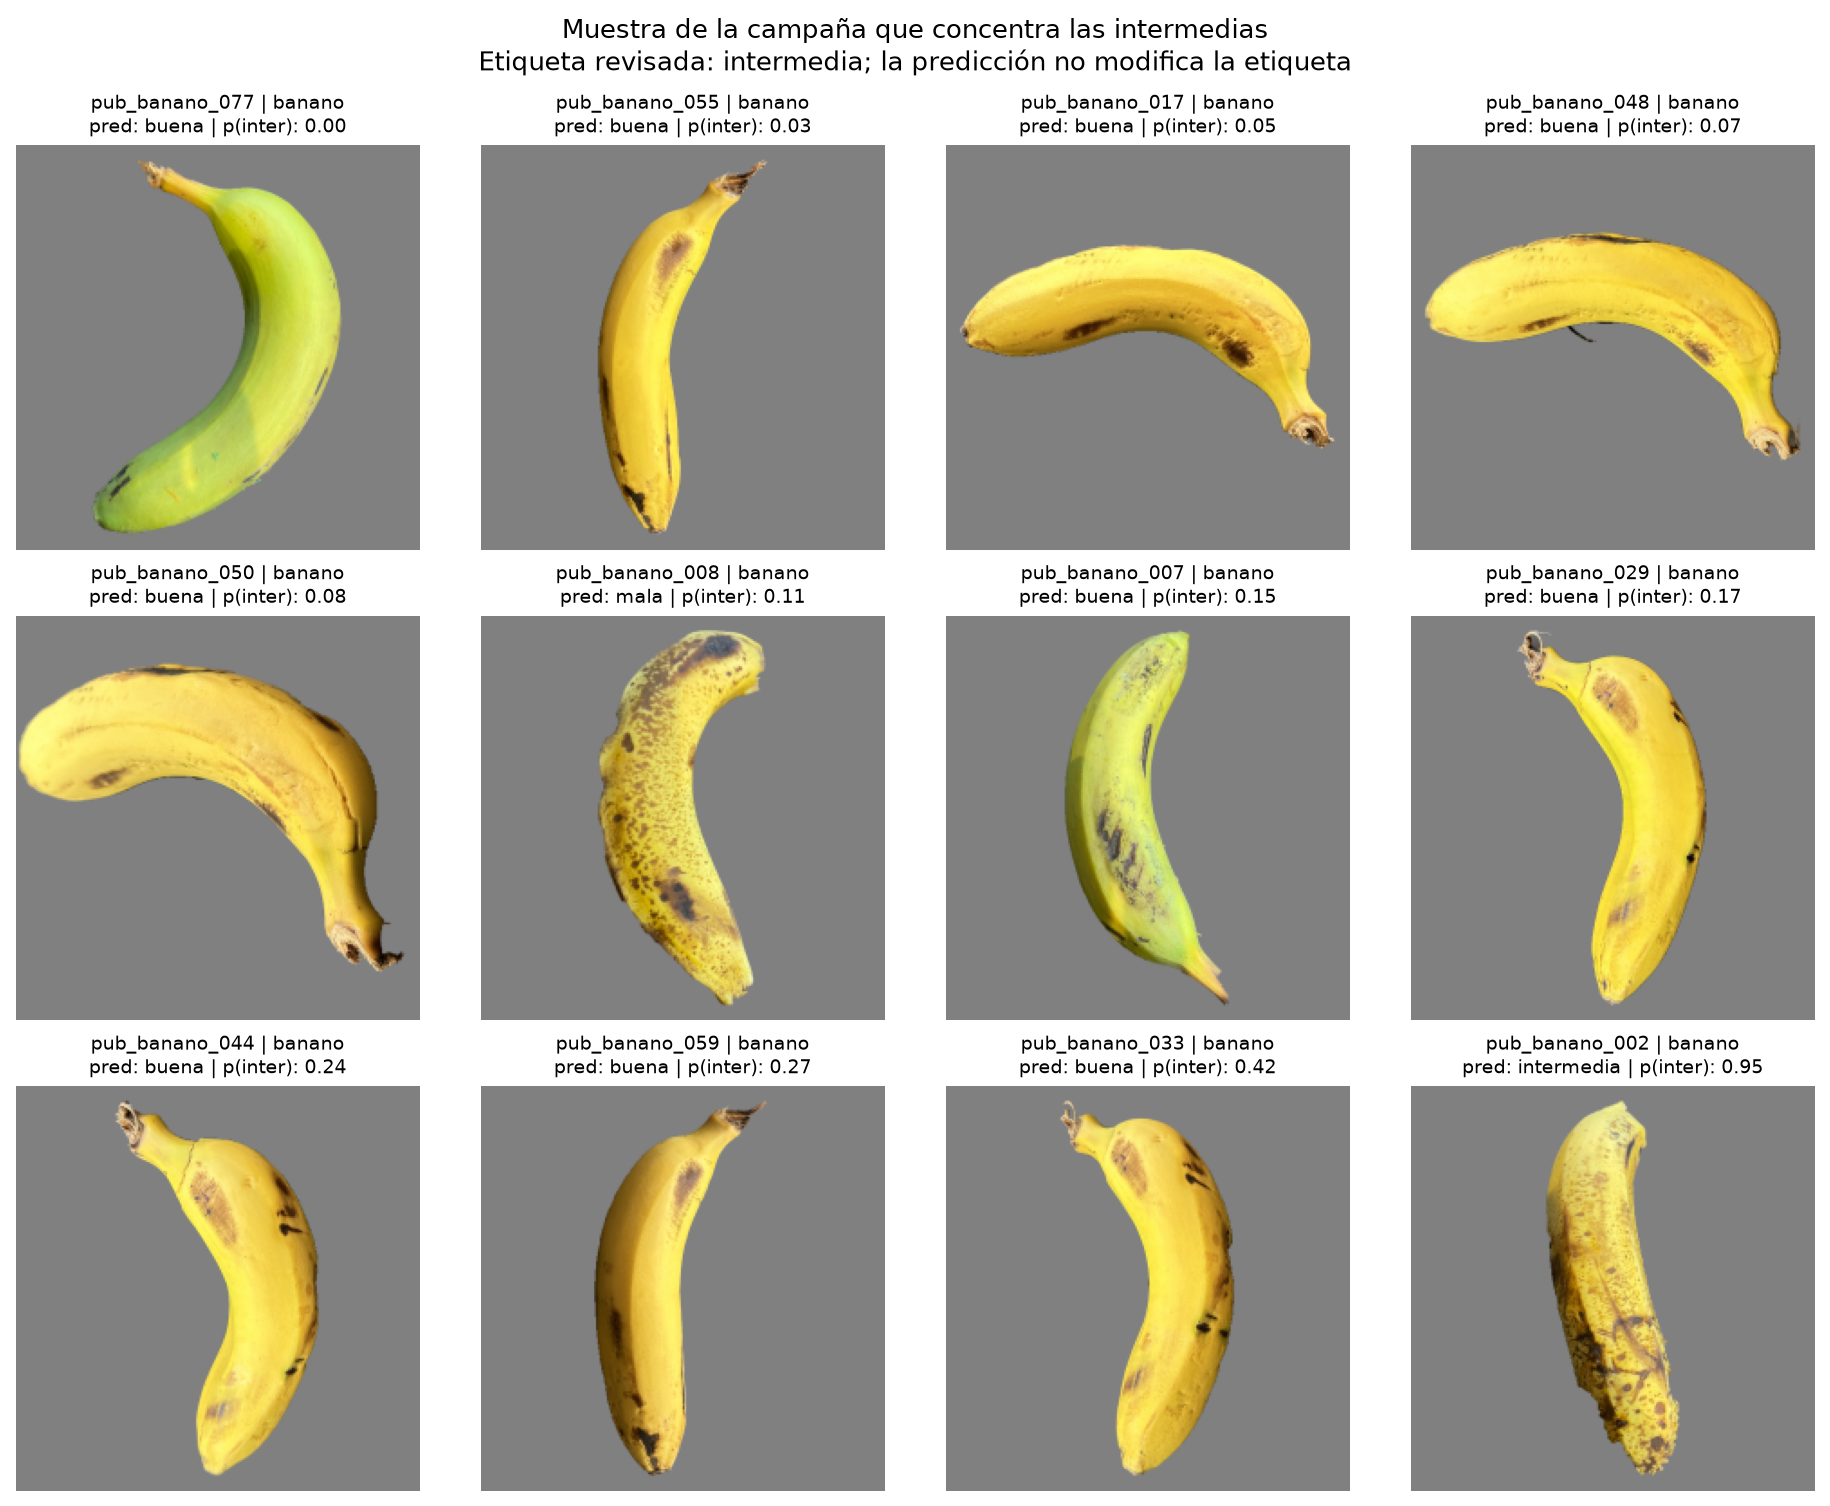

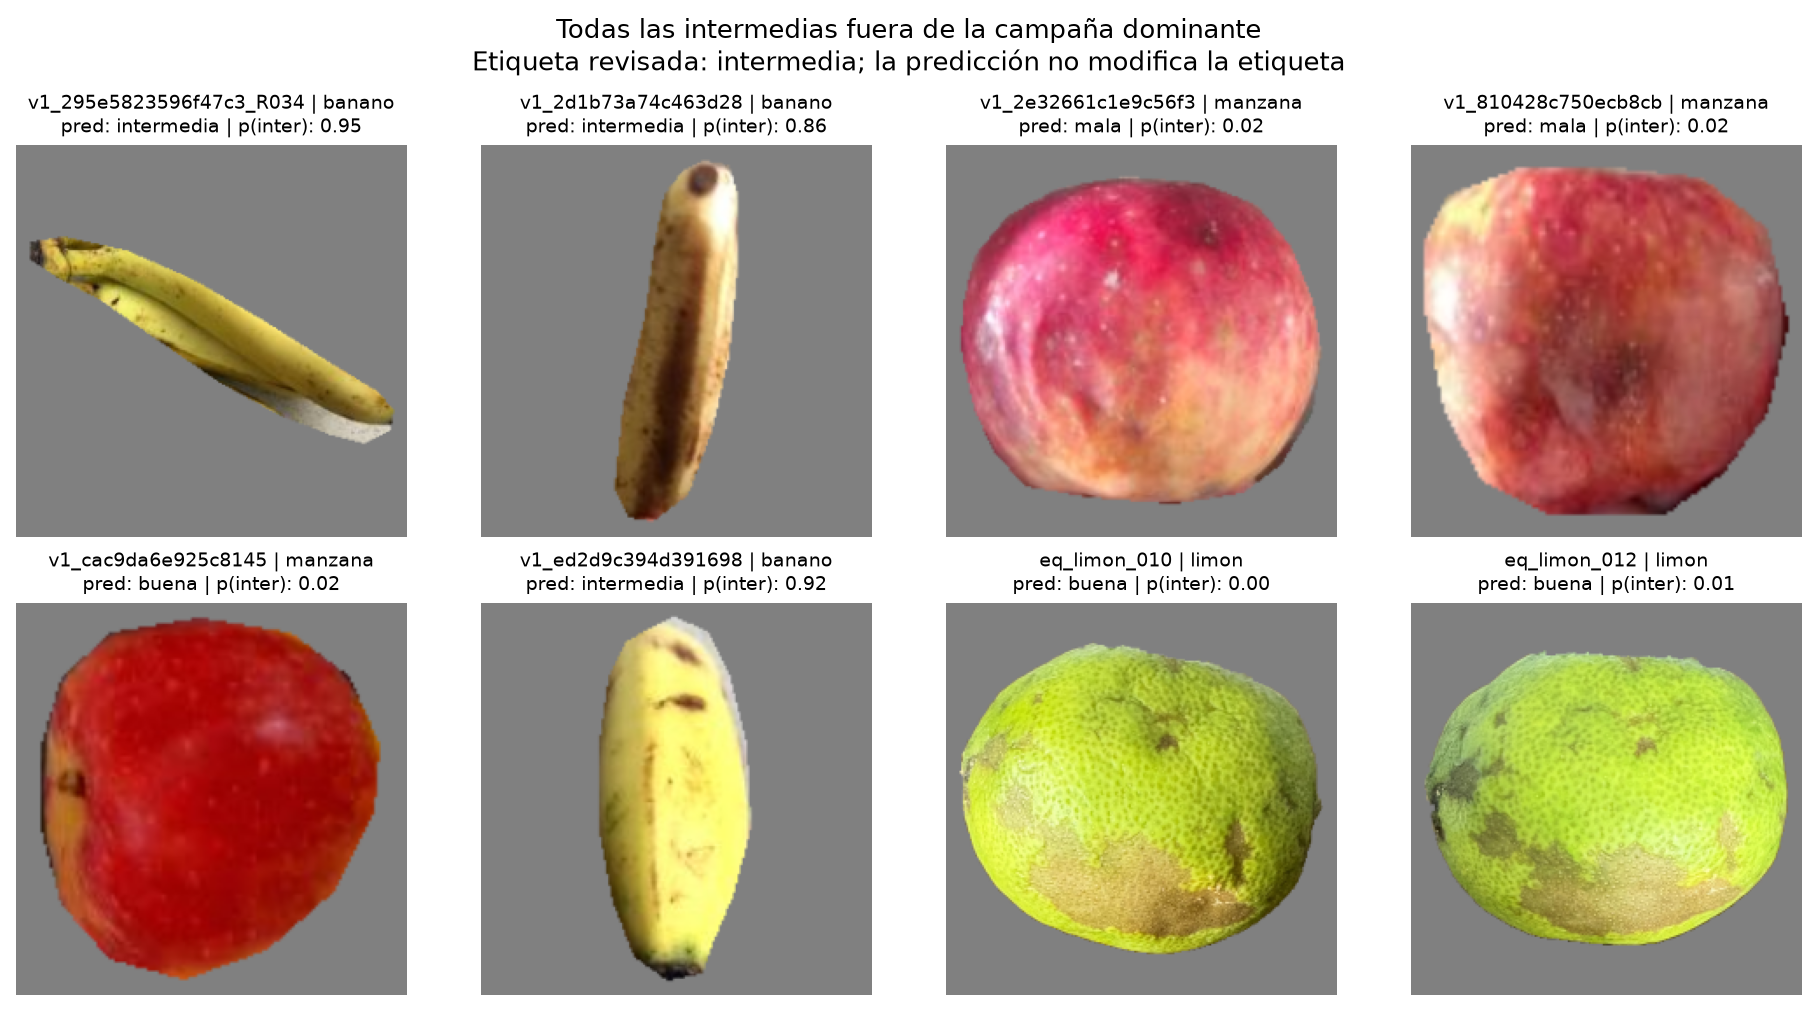

In [8]:
display(Image(filename=str(SALIDA / 'diagnostico_intermedia_campana.png'), width=1000))
display(Image(filename=str(SALIDA / 'diagnostico_intermedia_otros_grupos.png'), width=1000))

## Alternativas con la misma base

Se comparan regresión logística y SVM sobre los 576 rasgos de la CNN congelada; Extra Trees y HistGradientBoosting usan las 43 características de color, textura y forma. La vista original es la entrada visual en este cribado, sin aumentos. StandardScaler se ajusta dentro de cada división para los modelos lineales/SVM. Boosting tiene desactivada la parada temprana automática para evitar una división aleatoria que mezcle grupos.

La búsqueda y la selección de parámetros usan hasta tres bloques internos agrupados, con las mismas semillas del flujo CNN. Los bloques externos son los mismos de todos los modelos. Los espacios se guardan antes de entrenar, y la selección maximiza F1 macro interno; no se ajusta un umbral sobre las predicciones externas. Este cribado amplía el informe existente sin reemplazar los pesos actuales de CNN. Sigue siendo desarrollo, no una prueba independiente.

Referencias: [regresión logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html) y [HistGradientBoosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).

In [9]:
columnas_diagnostico = ['modelo', 'exactitud', 'f1_macro', 'precision_intermedia', 'recall_intermedia', 'f1_intermedia', 'aciertos_intermedia', 'predichas_intermedia', 'f1_macro_peso_grupo']
display(diagnostico['metricas_alternativas'][columnas_diagnostico].sort_values('f1_macro', ascending=False))
display(pd.read_csv(SALIDA / 'diagnostico_alternativas_bloques.csv'))
verificar(PROYECTO)

,modelo,exactitud,f1_macro,precision_intermedia,recall_intermedia,f1_intermedia,aciertos_intermedia,predichas_intermedia,f1_macro_peso_grupo
10,Gradient_Boosting,0.6495,0.4871,0.4130,0.2533,0.3140,19,46,0.4838
6,CNN_transferencia,0.7045,0.4725,0.4615,0.0800,0.1364,6,13,0.5313
2,Random_Forest_inicial,0.5464,0.4288,0.1864,0.1467,0.1642,11,59,0.4048
8,SVM_CNN,0.6701,0.4204,0.5455,0.0800,0.1395,6,11,0.4587
7,Logistica_CNN,0.6529,0.4007,0.4444,0.0533,0.0952,4,9,0.5193
4,Random_Forest_ajustado,0.4433,0.3877,0.1196,0.1467,0.1317,11,92,0.3665
3,SVM_ajustado,0.4467,0.3730,0.1379,0.1600,0.1481,12,87,0.3739
9,Extra_Trees,0.4227,0.3569,0.1099,0.1333,0.1205,10,91,0.3429
1,SVM_inicial,0.3952,0.2986,0.1236,0.1467,0.1341,11,89,0.3675
0,Referencia_mayoritaria,0.6907,0.2724,0.0000,0.0000,0.0000,0,0,0.2322


,modelo,exterior,exactitud,f1_macro,recall_macro,precision_intermedia,recall_intermedia,f1_intermedia,aciertos_intermedia,predichas_intermedia
0,Referencia_mayoritaria,1,0.9450,0.3239,0.3333,0.0000,0.0000,0.0000,0,0
1,Referencia_mayoritaria,2,0.8539,0.3071,0.3333,0.0000,0.0000,0.0000,0,0
2,Referencia_mayoritaria,3,0.2366,0.1275,0.3333,0.0000,0.0000,0.0000,0,0
3,SVM_inicial,1,0.8257,0.3630,0.4515,0.0000,0.0000,0.0000,0,0
4,SVM_inicial,2,0.1124,0.1438,0.2406,0.0411,0.5000,0.0759,3,73
5,SVM_inicial,3,0.1613,0.1682,0.4186,0.5000,0.1194,0.1928,8,16
6,Random_Forest_inicial,1,0.9450,0.4734,0.4935,0.0000,0.0000,0.0000,0,0
7,Random_Forest_inicial,2,0.4607,0.4161,0.5142,0.0889,0.6667,0.1569,4,45
8,Random_Forest_inicial,3,0.1613,0.2223,0.4288,0.5000,0.1045,0.1728,7,14
9,SVM_ajustado,1,0.3119,0.2498,0.2702,0.0000,0.0000,0.0000,0,64


Verificado diagnóstico: 3201 predicciones de 11 modelos; doce ajustes externos reproducidos.
Métricas, selección interna, referencias y separación de grupos correctas.


## Qué mejorar a partir del diagnóstico

Priorizar un criterio visual de calidad específico por fruta y una segunda revisión de los casos fronterizos, conservando el historial y sin cambiar etiquetas por conveniencia del modelo. Con las imágenes actuales pueden probarse fusión de rasgos CNN y características de máscara, ajuste interno de costes/umbrales, ponderación por grupo y un ajuste suave del último bloque convolucional. Cada experimento debe conservar las particiones externas y medir F1/precisión/recall de intermedia junto con el resultado global.

Las rotaciones y el sobremuestreo reutilizan la información existente; no aportan nuevos frutos o campañas. La clase intermedia representa calidad visual y la incertidumbre del clasificador se trata por separado. La diferencia de rendimiento entre bloques limita las conclusiones del promedio.